# CareerLens: Does AI Disclosure Affect Trust in Career Advice?

**A/B test analysis notebook** · CMU Heinz College · A/B Testing course project (Spring 2026)

Team: Egshiglen Batjargal, Chloe Xu, Sandy Yang

## Research question
Does labeling career advice as **AI-generated** (treatment: *"Generated by Claude"*) change how graduate students perceive it, compared with the same advice labeled as written by a **human professional** (control: *"Written by a MasterCard Careers professional"*)?

## Hypotheses
- **H1 (Credibility):** AI-attributed advice receives lower credibility and expertise ratings.
- **H2 (Quality):** AI-attributed advice is rated lower on relevance and practicality.
- **H3 (Behavioral intent):** Participants in the AI group are less willing to share the advice.

## Notebook outline
1. Setup and data loading
2. Summary statistics
3. Balance checks (randomization)
4. Average treatment effects (real, synthetic, combined)
5. Heterogeneous treatment effects (gender, age)
6. Power calculations
7. Real vs. LLM-synthetic data comparison


> **About the data.** The original survey responses are not included in this public repo, to protect respondent privacy.
> Put your own exports at `data/real_responses.csv` and `data/synthetic_responses.csv` (schema in `data/README.md`) and the notebook will use them.
> If those files are missing, the notebook generates a **simulated demo dataset** calibrated to the group means and standard deviations reported in our final report, so every cell still runs.
> **Numbers produced from the simulated data will differ from the report.** The headline results from the real study are listed in the repo README.


## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = "../data"
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

OUTCOMES = {
    "credibility": "Credibility (accurate and reliable)",
    "expertise":   "Expertise (source is knowledgeable)",
    "quality":     "Quality (relevant and practical)",
    "sharing":     "Sharing intent (share with a friend)",
}
COVARIATES = ["age_range", "sex", "program", "work_exp", "career_visit"]
COLORS = {"AI": "#6b8f71", "Human": "#5b5560"}

### 1.1 Load data (real exports if available, otherwise simulated demo data)

The simulation draws each outcome from a normal distribution with the group mean and SD from the report, rescales the draws to match those moments, then rounds and clips to the 0 to 10 scale.
The synthetic arm mimics the LLM-generated sample, where the AI vs. human gap essentially disappeared.

In [2]:
# Group-level moments reported in the final report: (mean, sd) per outcome
REAL_MOMENTS = {
    "Human": dict(n=44, credibility=(6.09, 2.24), expertise=(6.45, 1.77), quality=(5.84, 2.16), sharing=(4.20, 3.33)),
    "AI":    dict(n=41, credibility=(5.95, 1.48), expertise=(5.46, 1.80), quality=(5.49, 1.93), sharing=(4.37, 2.37)),
}
SYNTH_MOMENTS = {
    "Human": dict(n=1587, credibility=(5.99, 1.90), expertise=(5.95, 1.88), quality=(5.73, 2.05), sharing=(4.19, 2.90)),
    "AI":    dict(n=1413, credibility=(5.95, 1.96), expertise=(5.96, 1.91), quality=(5.63, 1.98), sharing=(4.35, 2.89)),
}
DEMOGRAPHICS = {
    "program":      (["MISM/MISM-BIDA", "MSPPM", "MSHCA", "MAM", "MEIM", "MSIT", "Other"], [.55, .15, .08, .06, .06, .05, .05]),
    "age_range":    (["18-22", "23-26", "27-30", "31+"], [.15, .65, .14, .06]),
    "sex":          (["Female", "Male", "Prefer not to say"], [.58, .40, .02]),
    "work_exp":     (["0-1", "1-3", "3-5", "5+"], [.55, .25, .12, .08]),
    "career_visit": (["Never", "Once a semester", "Once a month", "More than once a month"], [.30, .50, .12, .08]),
    "ai_pref":      (["Claude", "ChatGPT", "Gemini", "Other"], [.55, .33, .08, .04]),
}

def simulate(moments, source, seed):
    rng = np.random.default_rng(seed)
    frames = []
    for group, m in moments.items():
        n = m["n"]
        d = {"group": [group] * n, "source": [source] * n}
        for col, (levels, p) in DEMOGRAPHICS.items():
            d[col] = rng.choice(levels, size=n, p=p)
        for y in OUTCOMES:
            mu, sd = m[y]
            z = rng.normal(size=n)
            z = (z - z.mean()) / z.std(ddof=1)  # match the reported moments exactly before rounding
            d[y] = np.clip(np.round(mu + sd * z), 0, 10).astype(int)
        frames.append(pd.DataFrame(d))
    return pd.concat(frames, ignore_index=True)

real_path = os.path.join(DATA_DIR, "real_responses.csv")
synth_path = os.path.join(DATA_DIR, "synthetic_responses.csv")

if os.path.exists(real_path) and os.path.exists(synth_path):
    real = pd.read_csv(real_path).assign(source="real")
    synth = pd.read_csv(synth_path).assign(source="synthetic")
    DEMO = False
    print("Loaded real survey exports.")
else:
    real = simulate(REAL_MOMENTS, "real", seed=42)
    synth = simulate(SYNTH_MOMENTS, "synthetic", seed=7)
    DEMO = True
    print("DEMO MODE: data files not found, using simulated data calibrated to the report.")

combined = pd.concat([real, synth], ignore_index=True)
combined["treat"] = (combined["group"] == "AI").astype(int)
real, synth = combined[combined.source == "real"], combined[combined.source == "synthetic"]
print(f"Real n={len(real)}  |  Synthetic n={len(synth)}  |  Combined n={len(combined)}")
combined.head()

DEMO MODE: data files not found, using simulated data calibrated to the report.
Real n=85  |  Synthetic n=3000  |  Combined n=3085


,group,source,program,age_range,sex,work_exp,career_visit,ai_pref,credibility,expertise,quality,sharing,treat
0,Human,real,MSHCA,27-30,Female,1-3,Once a semester,Claude,8,7,6,7,0
1,Human,real,MISM/MISM-BIDA,27-30,Female,0-1,More than once a month,Claude,7,9,9,6,0
2,Human,real,MEIM,23-26,Female,1-3,Once a month,ChatGPT,5,3,1,0,0
3,Human,real,MSPPM,23-26,Male,0-1,Once a semester,Gemini,6,8,4,0,0
4,Human,real,MISM/MISM-BIDA,23-26,Female,5+,Once a month,Claude,3,6,7,5,0


## 2. Summary statistics

In [3]:
def summary(df, label):
    print(f"--- {label} (n={len(df)}) ---")
    display(df[list(OUTCOMES)].describe().T[["count", "mean", "std", "min", "50%", "max"]])

summary(real, "Real data, full sample")
for g in ["Human", "AI"]:
    summary(real[real.group == g], f"Real data, {g} group")

--- Real data, full sample (n=85) ---


,count,mean,std,min,50%,max
credibility,85.0,6.012,1.842,0.0,6.0,10.0
expertise,85.0,5.965,1.835,2.0,6.0,9.0
quality,85.0,5.635,2.069,1.0,6.0,10.0
sharing,85.0,4.376,2.623,0.0,5.0,10.0


--- Real data, Human group (n=44) ---


,count,mean,std,min,50%,max
credibility,44.0,6.068,2.139,0.0,6.0,10.0
expertise,44.0,6.386,1.794,2.0,7.0,9.0
quality,44.0,5.727,2.203,1.0,6.0,10.0
sharing,44.0,4.364,2.926,0.0,4.5,10.0


--- Real data, AI group (n=41) ---


,count,mean,std,min,50%,max
credibility,41.0,5.951,1.482,2.0,6.0,9.0
expertise,41.0,5.512,1.791,2.0,6.0,9.0
quality,41.0,5.537,1.938,2.0,5.0,9.0
sharing,41.0,4.390,2.290,0.0,5.0,8.0


In [4]:
for g in ["Human", "AI"]:
    summary(synth[synth.group == g], f"Synthetic data, {g} group")

--- Synthetic data, Human group (n=1587) ---


,count,mean,std,min,50%,max
credibility,1587.0,5.979,1.879,0.0,6.0,10.0
expertise,1587.0,5.945,1.885,1.0,6.0,10.0
quality,1587.0,5.726,2.033,0.0,6.0,10.0
sharing,1587.0,4.260,2.662,0.0,4.0,10.0


--- Synthetic data, AI group (n=1413) ---


,count,mean,std,min,50%,max
credibility,1413.0,5.946,1.945,0.0,6.0,10.0
expertise,1413.0,5.946,1.874,0.0,6.0,10.0
quality,1413.0,5.626,1.983,0.0,6.0,10.0
sharing,1413.0,4.425,2.686,0.0,4.0,10.0


## 3. Balance checks

If randomization worked, pre-treatment covariates should be independent of group assignment.
We run a chi-square test of independence for each covariate. A p-value above 0.05 means no detectable imbalance.

In [5]:
def balance_check(df):
    rows = []
    for cov in COVARIATES:
        tab = pd.crosstab(df[cov], df["group"])
        chi2, p, dof, _ = stats.chi2_contingency(tab)
        props = tab / tab.sum()
        rows.append(dict(covariate=cov, chi2=chi2, df=dof, p_value=p,
                         max_prop_gap=(props["AI"] - props["Human"]).abs().max(),
                         balanced=p > 0.05))
    return pd.DataFrame(rows)

print("Real respondents"); display(balance_check(real))
print("LLM synthetic");    display(balance_check(synth))

Real respondents


,covariate,chi2,df,p_value,max_prop_gap,balanced
0,age_range,3.257,3,0.354,0.060,True
1,sex,2.760,2,0.252,0.094,True
2,program,6.456,6,0.374,0.108,True
3,work_exp,2.014,3,0.570,0.154,True
4,career_visit,0.448,3,0.930,0.048,True


LLM synthetic


,covariate,chi2,df,p_value,max_prop_gap,balanced
0,age_range,0.551,3,0.907,0.011,True
1,sex,5.659,2,0.059,0.040,True
2,program,1.002,6,0.986,0.006,True
3,work_exp,3.400,3,0.334,0.023,True
4,career_visit,8.353,3,0.039,0.024,False


## 4. Average treatment effects (ATE)

ATE = mean(AI) minus mean(Human). We use Welch's two-sample t-test (unequal variances) and report a 95% CI and Cohen's d.
A negative ATE means AI attribution lowered the rating.

In [6]:
def welch_ate(y_t, y_c):
    y_t, y_c = np.asarray(y_t, float), np.asarray(y_c, float)
    nt, nc = len(y_t), len(y_c)
    vt, vc = y_t.var(ddof=1), y_c.var(ddof=1)
    diff = y_t.mean() - y_c.mean()
    se = np.sqrt(vt / nt + vc / nc)
    dof = (vt / nt + vc / nc) ** 2 / ((vt / nt) ** 2 / (nt - 1) + (vc / nc) ** 2 / (nc - 1))
    t = diff / se
    p = 2 * stats.t.sf(abs(t), dof)
    half = stats.t.ppf(0.975, dof) * se
    pooled_sd = np.sqrt(((nt - 1) * vt + (nc - 1) * vc) / (nt + nc - 2))
    return dict(n_AI=nt, n_Human=nc, AI_mean=y_t.mean(), Human_mean=y_c.mean(), ATE=diff,
                CI_low=diff - half, CI_high=diff + half, p_value=p, cohens_d=diff / pooled_sd)

def sig(p):
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "n.s."

def ate_table(df):
    rows = []
    for y in OUTCOMES:
        r = welch_ate(df.loc[df.treat == 1, y], df.loc[df.treat == 0, y])
        rows.append({"outcome": y, **r, "sig": sig(r["p_value"])})
    return pd.DataFrame(rows).set_index("outcome")

ate_real, ate_synth, ate_comb = ate_table(real), ate_table(synth), ate_table(combined)
print("Real data (primary analysis)"); display(ate_real)
print("Synthetic data only");          display(ate_synth)
print("Combined real + synthetic");    display(ate_comb)

Real data (primary analysis)


,n_AI,n_Human,AI_mean,Human_mean,ATE,CI_low,CI_high,p_value,cohens_d,sig
outcome,,,,,,,,,,
credibility,41,44,5.951,6.068,-0.117,-0.908,0.674,0.769,-0.063,n.s.
expertise,41,44,5.512,6.386,-0.874,-1.648,-0.100,0.027,-0.488,*
quality,41,44,5.537,5.727,-0.191,-1.084,0.703,0.672,-0.092,n.s.
sharing,41,44,4.390,4.364,0.027,-1.103,1.157,0.963,0.010,n.s.


Synthetic data only


,n_AI,n_Human,AI_mean,Human_mean,ATE,CI_low,CI_high,p_value,cohens_d,sig
outcome,,,,,,,,,,
credibility,1413,1587,5.946,5.979,-3.236e-02,-0.170,0.105,0.644,-1.694e-02,n.s.
expertise,1413,1587,5.946,5.945,9.566e-04,-0.134,0.136,0.989,5.088e-04,n.s.
quality,1413,1587,5.626,5.726,-9.957e-02,-0.244,0.044,0.175,-4.954e-02,n.s.
sharing,1413,1587,4.425,4.260,1.651e-01,-0.027,0.357,0.092,6.177e-02,n.s.


Combined real + synthetic


,n_AI,n_Human,AI_mean,Human_mean,ATE,CI_low,CI_high,p_value,cohens_d,sig
outcome,,,,,,,,,,
credibility,1454,1631,5.946,5.981,-0.035,-0.170,0.10,0.615,-0.018,n.s.
expertise,1454,1631,5.933,5.956,-0.023,-0.156,0.11,0.732,-0.012,n.s.
quality,1454,1631,5.624,5.726,-0.102,-0.244,0.04,0.159,-0.051,n.s.
sharing,1454,1631,4.424,4.263,0.161,-0.028,0.35,0.094,0.060,n.s.


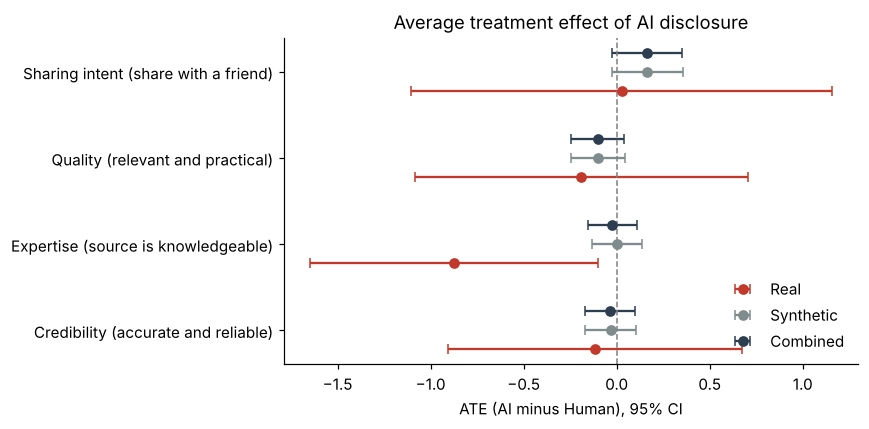

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = list(OUTCOMES)
for i, (name, tab, c) in enumerate([("Real", ate_real, "#c0392b"), ("Synthetic", ate_synth, "#7f8c8d"), ("Combined", ate_comb, "#2c3e50")]):
    y = np.arange(len(labels)) + (i - 1) * 0.22
    ax.errorbar(tab["ATE"], y, xerr=[tab["ATE"] - tab["CI_low"], tab["CI_high"] - tab["ATE"]],
                fmt="o", color=c, capsize=3, label=name)
ax.axvline(0, color="grey", lw=1, ls="--")
ax.set_yticks(range(len(labels))); ax.set_yticklabels([OUTCOMES[l] for l in labels])
ax.set_xlabel("ATE (AI minus Human), 95% CI"); ax.set_title("Average treatment effect of AI disclosure")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ate_forest_plot.png", bbox_inches="tight"); plt.show()

## 5. Heterogeneous treatment effects (HTE)

Does the effect differ by gender or age? These subgroup cells are small (often under 30 per arm), so treat the results as **exploratory**.

In [8]:
def hte_table(df, by, min_n=3):
    rows = []
    for level, sub in df.groupby(by):
        t, c = sub[sub.treat == 1], sub[sub.treat == 0]
        if len(t) < min_n or len(c) < min_n:
            continue
        for y in OUTCOMES:
            r = welch_ate(t[y], c[y])
            rows.append({by: level, "outcome": y, **r, "sig": sig(r["p_value"])})
    return pd.DataFrame(rows)

cols = ["n_AI", "n_Human", "AI_mean", "Human_mean", "ATE", "CI_low", "CI_high", "p_value", "sig"]
print("Real data, by gender"); display(hte_table(real, "sex").set_index(["sex", "outcome"])[cols])
print("Real data, by age");    display(hte_table(real, "age_range").set_index(["age_range", "outcome"])[cols])

Real data, by gender


n_AI  n_Human  AI_mean  Human_mean    ATE  CI_low  \
sex    outcome                                                          
Female credibility    27       27    5.704       6.222 -0.519  -1.636   
       expertise      27       27    5.222       6.407 -1.185  -2.153   
       quality        27       27    5.444       5.593 -0.148  -1.400   
       sharing        27       27    4.519       4.370  0.148  -1.293   
Male   credibility    12       17    6.333       5.824  0.510  -0.595   
       expertise      12       17    6.000       6.353 -0.353  -1.726   
       quality        12       17    5.583       5.941 -0.358  -1.667   
       sharing        12       17    4.083       4.353 -0.270  -2.352   

                    CI_high  p_value   sig  
sex    outcome                              
Female credibility    0.599    0.355  n.s.  
       expertise     -0.218    0.017     *  
       quality        1.104    0.813  n.s.  
       sharing        1.589    0.837  n.s.  
Male   credibility    1.614    0.352  n.s.  
       expertise      1.020    0.602  n.s.  
       quality        0.952    0.579  n.s.  
       sharing        1.813    0.792  n.s.

Real data, by age


n_AI  n_Human  AI_mean  Human_mean    ATE  CI_low  \
age_range outcome                                                          
18-22     credibility     5        8    5.600       6.125 -0.525  -2.900   
          expertise       5        8    4.800       6.000 -1.200  -3.410   
          quality         5        8    6.400       4.250  2.150   0.023   
          sharing         5        8    3.400       5.250 -1.850  -5.205   
23-26     credibility    28       32    6.071       6.125 -0.054  -1.011   
          expertise      28       32    5.500       6.375 -0.875  -1.777   
          quality        28       32    5.464       5.844 -0.379  -1.466   
          sharing        28       32    4.214       4.000  0.214  -1.147   
27-30     credibility     6        4    5.500       5.500  0.000  -5.770   
          expertise       6        4    5.333       7.250 -1.917  -4.563   
          quality         6        4    5.333       7.750 -2.417  -4.917   
          sharing         6        4    5.500       5.500  0.000  -2.096   

                       CI_high  p_value   sig  
age_range outcome                              
18-22     credibility    1.850    0.605  n.s.  
          expertise      1.010    0.252  n.s.  
          quality        4.277    0.048     *  
          sharing        1.505    0.243  n.s.  
23-26     credibility    0.904    0.911  n.s.  
          expertise      0.027    0.057  n.s.  
          quality        0.708    0.487  n.s.  
          sharing        1.576    0.754  n.s.  
27-30     credibility    5.770    1.000  n.s.  
          expertise      0.730    0.133  n.s.  
          quality        0.084    0.056  n.s.  
          sharing        2.096    1.000  n.s.

In [9]:
print("Combined data, by gender"); display(hte_table(combined, "sex").set_index(["sex", "outcome"])[cols])
print("Combined data, by age");    display(hte_table(combined, "age_range").set_index(["age_range", "outcome"])[cols])

Combined data, by gender


n_AI  n_Human  AI_mean  Human_mean        ATE  \
sex               outcome                                                      
Female            credibility   837     1000    5.932       5.956 -2.410e-02   
                  expertise     837     1000    5.955       5.995 -4.040e-02   
                  quality       837     1000    5.631       5.695 -6.418e-02   
                  sharing       837     1000    4.479       4.235  2.441e-01   
Male              credibility   581      603    5.960       6.032 -7.110e-02   
                  expertise     581      603    5.910       5.910  5.138e-05   
                  quality       581      603    5.645       5.784 -1.390e-01   
                  sharing       581      603    4.317       4.330 -1.332e-02   
Prefer not to say credibility    36       28    6.056       5.786  2.698e-01   
                  expertise      36       28    5.806       5.571  2.341e-01   
                  quality        36       28    5.111       5.571 -4.603e-01   
                  sharing        36       28    4.889       3.821  1.067e+00   

                               CI_low  CI_high  p_value   sig  
sex               outcome                                      
Female            credibility  -0.199    0.151    0.787  n.s.  
                  expertise    -0.212    0.131    0.645  n.s.  
                  quality      -0.248    0.120    0.493  n.s.  
                  sharing       0.002    0.486    0.048     *  
Male              credibility  -0.292    0.150    0.529  n.s.  
                  expertise    -0.216    0.216    1.000  n.s.  
                  quality      -0.371    0.093    0.240  n.s.  
                  sharing      -0.324    0.297    0.933  n.s.  
Prefer not to say credibility  -0.598    1.137    0.533  n.s.  
                  expertise    -0.725    1.194    0.627  n.s.  
                  quality      -1.290    0.369    0.272  n.s.  
                  sharing      -0.340    2.475    0.134  n.s.

Combined data, by age


n_AI  n_Human  AI_mean  Human_mean    ATE  CI_low  \
age_range outcome                                                          
18-22     credibility   206      225    5.951       5.822  0.129  -0.231   
          expertise     206      225    6.019       6.009  0.011  -0.348   
          quality       206      225    5.379       5.640 -0.261  -0.646   
          sharing       206      225    4.155       4.356 -0.200  -0.724   
23-26     credibility   936     1069    5.899       6.002 -0.103  -0.272   
          expertise     936     1069    5.966       5.978 -0.013  -0.177   
          quality       936     1069    5.636       5.759 -0.123  -0.299   
          sharing       936     1069    4.452       4.266  0.186  -0.048   
27-30     credibility   232      247    6.030       5.955  0.075  -0.247   
          expertise     232      247    5.823       5.846 -0.023  -0.360   
          quality       232      247    5.784       5.684  0.100  -0.259   
          sharing       232      247    4.616       4.101  0.515   0.048   
31+       credibility    80       90    6.250       6.200  0.050  -0.605   
          expertise      80       90    5.650       5.867 -0.217  -0.790   
          quality        80       90    5.650       5.667 -0.017  -0.654   
          sharing        80       90    4.237       4.444 -0.207  -1.028   

                       CI_high  p_value   sig  
age_range outcome                              
18-22     credibility    0.490    0.481  n.s.  
          expertise      0.369    0.954  n.s.  
          quality        0.123    0.182  n.s.  
          sharing        0.323    0.453  n.s.  
23-26     credibility    0.065    0.229  n.s.  
          expertise      0.152    0.880  n.s.  
          quality        0.053    0.170  n.s.  
          sharing        0.420    0.119  n.s.  
27-30     credibility    0.396    0.648  n.s.  
          expertise      0.315    0.894  n.s.  
          quality        0.459    0.583  n.s.  
          sharing        0.983    0.031     *  
31+       credibility    0.705    0.880  n.s.  
          expertise      0.357    0.457  n.s.  
          quality        0.621    0.959  n.s.  
          sharing        0.614    0.619  n.s.

## 6. Power calculations

For each outcome we take the observed Cohen's d from the real data and ask two questions.
What power did we have with about 41 participants per group? How many per group would we need for 80% and 90% power (two-sided, alpha = 0.05)?

In [10]:
analysis = TTestIndPower()
n_per_group = int(real.groupby("group").size().min())
rows = []
for y in OUTCOMES:
    d = abs(ate_real.loc[y, "cohens_d"])
    size = "large" if d >= .5 else "medium" if d >= .3 else "small"
    obs_power = analysis.power(effect_size=d, nobs1=n_per_group, alpha=0.05, ratio=1.0)
    need = lambda pw: int(np.ceil(analysis.solve_power(effect_size=d, power=pw, alpha=0.05, ratio=1.0))) if d > 0.01 else np.inf
    rows.append(dict(outcome=y, cohens_d=d, effect=size, observed_power=obs_power,
                     powered_80=obs_power >= .8, n_per_group_80=need(.8), n_per_group_90=need(.9),
                     current_n_per_group=n_per_group))
power_tbl = pd.DataFrame(rows).set_index("outcome")
power_tbl

,cohens_d,effect,observed_power,powered_80,n_per_group_80,n_per_group_90,current_n_per_group
outcome,,,,,,,
credibility,0.063,small,0.059,False,3937,5271,41
expertise,0.488,medium,0.588,False,67,90,41
quality,0.092,small,0.069,False,1868,2501,41
sharing,0.010,small,0.050,False,154395,206692,41


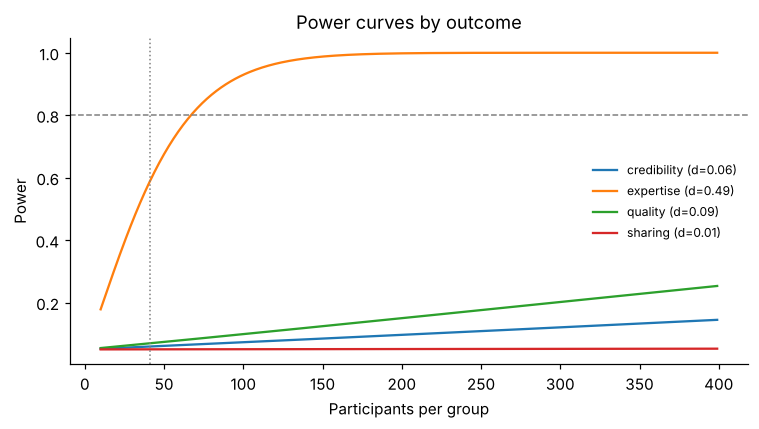

In [11]:
ns = np.arange(10, 400)
fig, ax = plt.subplots(figsize=(7, 4))
for y in OUTCOMES:
    d = abs(ate_real.loc[y, "cohens_d"])
    ax.plot(ns, analysis.power(effect_size=d, nobs1=ns, alpha=0.05), label=f"{y} (d={d:.2f})")
ax.axhline(0.8, color="grey", ls="--", lw=1); ax.axvline(n_per_group, color="grey", ls=":", lw=1)
ax.set_xlabel("Participants per group"); ax.set_ylabel("Power"); ax.set_title("Power curves by outcome")
ax.legend(frameon=False, fontsize=8); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/power_curves.png", bbox_inches="tight"); plt.show()

## 7. Real vs. LLM-synthetic data

The course required augmenting the human sample with 1,000+ LLM-generated responses. We generated 3,000.
The key question: did the synthetic data reproduce the **treatment effect**, or only the overall distributions?

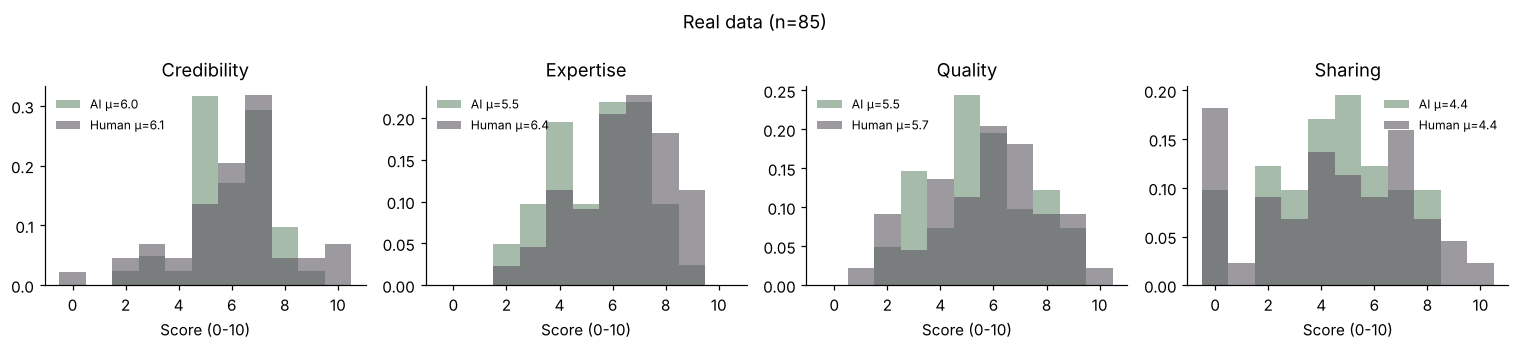

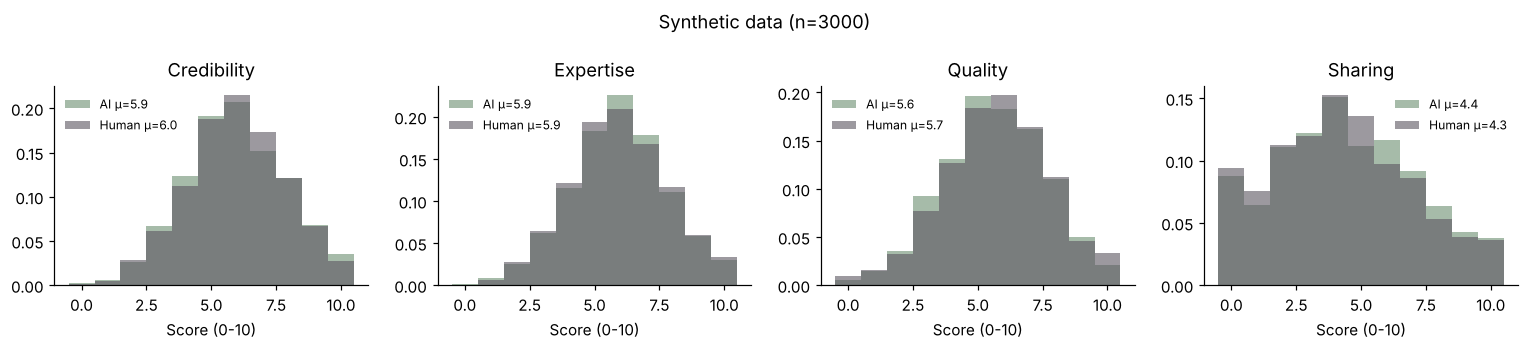

In [12]:
def plot_dists(df, title, fname):
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=False)
    bins = np.arange(-0.5, 11.5, 1)
    for ax, y in zip(axes, OUTCOMES):
        for g in ["AI", "Human"]:
            v = df.loc[df.group == g, y]
            ax.hist(v, bins=bins, density=True, alpha=0.6, color=COLORS[g], label=f"{g} μ={v.mean():.1f}")
        ax.set_title(y.capitalize()); ax.set_xlabel("Score (0-10)"); ax.legend(frameon=False, fontsize=8)
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{fname}", bbox_inches="tight"); plt.show()

plot_dists(real, f"Real data (n={len(real)})", "dist_real.png")
plot_dists(synth, f"Synthetic data (n={len(synth)})", "dist_synthetic.png")

In [13]:
effect_compare = pd.DataFrame({
    "d_real": ate_real["cohens_d"], "p_real": ate_real["p_value"],
    "d_synthetic": ate_synth["cohens_d"], "p_synthetic": ate_synth["p_value"],
})
effect_compare["attenuation"] = 1 - effect_compare["d_synthetic"].abs() / effect_compare["d_real"].abs()
effect_compare

,d_real,p_real,d_synthetic,p_synthetic,attenuation
outcome,,,,,
credibility,-0.063,0.769,-1.694e-02,0.644,0.732
expertise,-0.488,0.027,5.088e-04,0.989,0.999
quality,-0.092,0.672,-4.954e-02,0.175,0.460
sharing,0.010,0.963,6.177e-02,0.092,-5.126


## 8. Takeaways (from the real study, n = 85)

- **H1 partially supported.** AI attribution lowered perceived **expertise** by about one point (ATE = −0.99, p = 0.012, Cohen's d ≈ 0.56). Credibility did not change significantly.
- **H2 and H3 not supported.** Quality and sharing intent showed no significant differences (all p > 0.40).
- **Exploratory HTE.** The expertise penalty was concentrated among female respondents (ATE = −1.22, p = 0.035) and the 23 to 26 age group (ATE = −1.37, p = 0.006).
- **Power.** Only expertise was close to adequately powered (≈ 0.71). The other outcomes would need roughly 500 to 5,000+ participants per group.
- **Synthetic data caveat.** The LLM-generated sample matched the marginal distributions but **washed out the treatment effect** (d ≈ 0.56 → 0.01). Primary inference should rely on real responses only.

*If you are running this notebook in demo mode, your numbers will differ. Load the real exports to reproduce these results.*